# Employee Salary Prediction

## Data Science Mini Project

**Problem statement:** Predict an employee's salary using employee details such as age, gender, education level, job title, and years of experience. This is a **regression problem** because Salary is a numerical target variable.

**Dataset:** `Salary_Data.csv`

### Dataset columns
- `Age`
- `Gender`
- `Education Level`
- `Job Title`
- `Years of Experience`
- `Salary`


## 3.1 Load and Inspect

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Salary_Data.csv")

print(df.shape)
print(df.info())
print(df.isnull().sum())


(6704, 6)
<class 'pandas.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   str    
 2   Education Level      6701 non-null   str    
 3   Job Title            6702 non-null   str    
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), str(3)
memory usage: 314.4 KB
None
Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64


In [2]:
print(df.head())
print(df.describe())
print("Duplicate rows:", df.duplicated().sum())


    Age  Gender Education Level          Job Title  Years of Experience  \
0  32.0    Male      Bachelor's  Software Engineer                  5.0   
1  28.0  Female        Master's       Data Analyst                  3.0   
2  45.0    Male             PhD     Senior Manager                 15.0   
3  36.0  Female      Bachelor's    Sales Associate                  7.0   
4  52.0    Male        Master's           Director                 20.0   

     Salary  
0   90000.0  
1   65000.0  
2  150000.0  
3   60000.0  
4  200000.0  
               Age  Years of Experience         Salary
count  6702.000000          6701.000000    6699.000000
mean     33.620859             8.094687  115326.964771
std       7.614633             6.059003   52786.183911
min      21.000000             0.000000     350.000000
25%      28.000000             3.000000   70000.000000
50%      32.000000             7.000000  115000.000000
75%      38.000000            12.000000  160000.000000
max      62.000000       

### Dataset Description

The dataset contains employee information used to predict salary.

| Column | Description |
|---|---|
| Age | Age of employee |
| Gender | Gender of employee |
| Education Level | Education qualification |
| Job Title | Employee's job title |
| Years of Experience | Total years of experience |
| Salary | Employee salary (target) |

**Problem type:** Regression  
**Target variable:** `Salary`


## 3.2 Clean and Preprocess

In [3]:
data = df.copy()

# Missing values
data["Age"] = data["Age"].fillna(data["Age"].median())

data["Years of Experience"] = data["Years of Experience"].fillna(
    data["Years of Experience"].median()
)

data["Gender"] = data["Gender"].fillna(
    data["Gender"].mode()[0]
)

data["Education Level"] = data["Education Level"].fillna(
    data["Education Level"].mode()[0]
)

data["Job Title"] = data["Job Title"].fillna(
    data["Job Title"].mode()[0]
)

# Remove rows where target Salary is missing
data = data.dropna(subset=["Salary"])

# Remove duplicate rows
data = data.drop_duplicates()

print(data.head())
print("\nMissing values after cleaning:")
print(data.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(data.duplicated().sum())


    Age  Gender Education Level          Job Title  Years of Experience  \
0  32.0    Male      Bachelor's  Software Engineer                  5.0   
1  28.0  Female        Master's       Data Analyst                  3.0   
2  45.0    Male             PhD     Senior Manager                 15.0   
3  36.0  Female      Bachelor's    Sales Associate                  7.0   
4  52.0    Male        Master's           Director                 20.0   

     Salary  
0   90000.0  
1   65000.0  
2  150000.0  
3   60000.0  
4  200000.0  

Missing values after cleaning:
Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

Duplicate rows after cleaning:
0


### Justification to write

Median is used for numerical missing values because it is less affected by extreme values. Mode is used for categorical variables because it represents the most common category. Rows with missing Salary are removed because Salary is the target variable required for supervised learning. Duplicate records are removed so that repeated observations do not receive extra influence during model training.

Potential outliers are checked but are not automatically removed because unusually high or low salaries may represent legitimate employee records.


In [4]:
# Outlier check using IQR

def check_outliers(column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = ((data[column] < lower) | (data[column] > upper)).sum()
    return q1, q3, lower, upper, count

for column in ["Age", "Years of Experience", "Salary"]:
    q1, q3, lower, upper, count = check_outliers(column)
    print(column)
    print("Q1:", q1)
    print("Q3:", q3)
    print("Lower bound:", lower)
    print("Upper bound:", upper)
    print("Potential outliers:", count)
    print()


Age
Q1: 29.0
Q3: 41.0
Lower bound: 11.0
Upper bound: 59.0
Potential outliers: 6

Years of Experience
Q1: 3.0
Q3: 13.0
Lower bound: -12.0
Upper bound: 28.0
Potential outliers: 22

Salary
Q1: 70000.0
Q3: 160000.0
Lower bound: -65000.0
Upper bound: 295000.0
Potential outliers: 0



## 3.3 Visualization

### 1. Salary Distribution

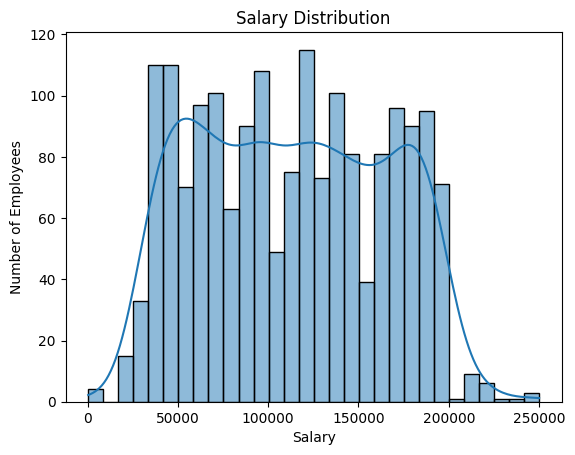

In [5]:
sns.histplot(data=data, x="Salary", kde=True, bins=30)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")

plt.show()


**Observation:** The histogram shows the distribution and spread of employee salaries.

### 2. Salary by Education Level

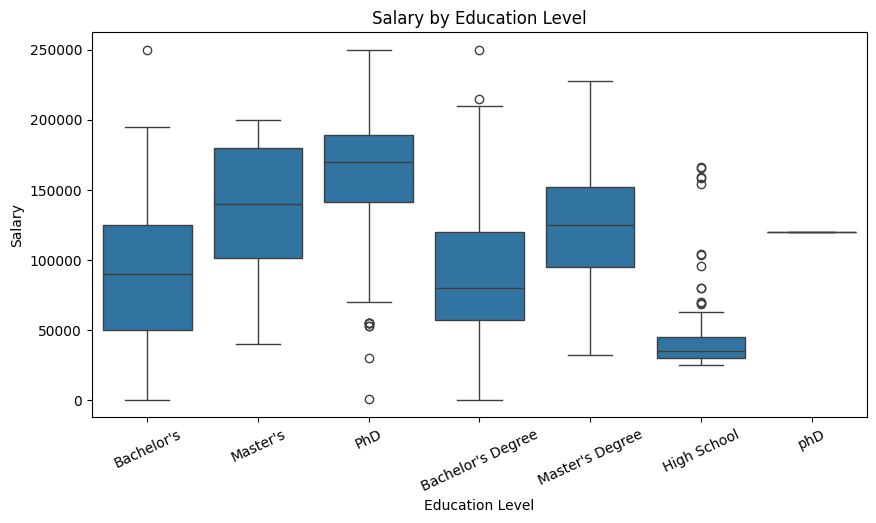

In [6]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x="Education Level",
    y="Salary",
    data=data
)

plt.title("Salary by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Salary")

plt.xticks(rotation=25)

plt.show()


**Observation:** Salary distributions vary across education levels, suggesting that education may be related to salary.

### 3. Salary by Gender

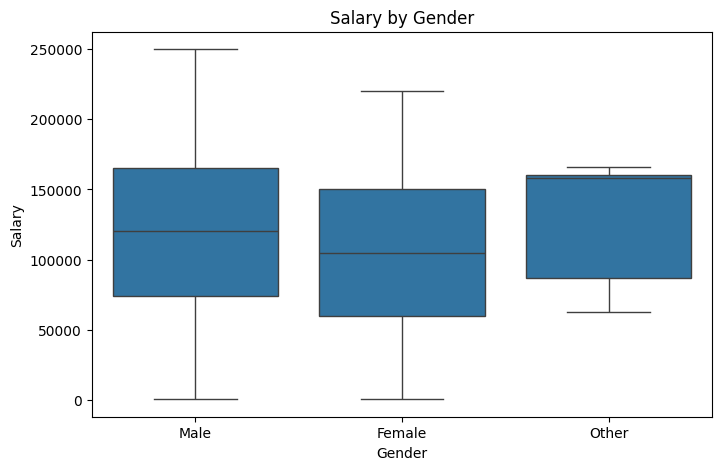

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Gender",
    y="Salary",
    data=data
)

plt.title("Salary by Gender")
plt.xlabel("Gender")
plt.ylabel("Salary")

plt.show()


**Observation:** The boxplot compares the salary distributions across gender categories.

### 4. Years of Experience vs Salary

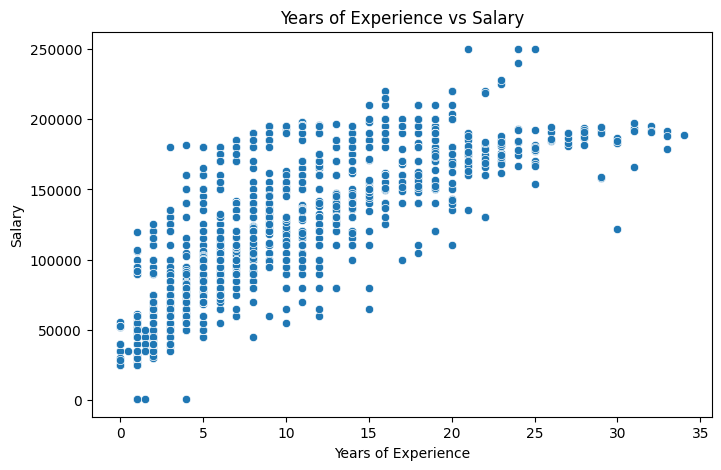

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Years of Experience",
    y="Salary",
    data=data
)

plt.title("Years of Experience vs Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")

plt.show()


**Observation:** The scatter plot shows the relationship between work experience and salary; salary generally tends to increase with experience.

### 5. Age vs Salary

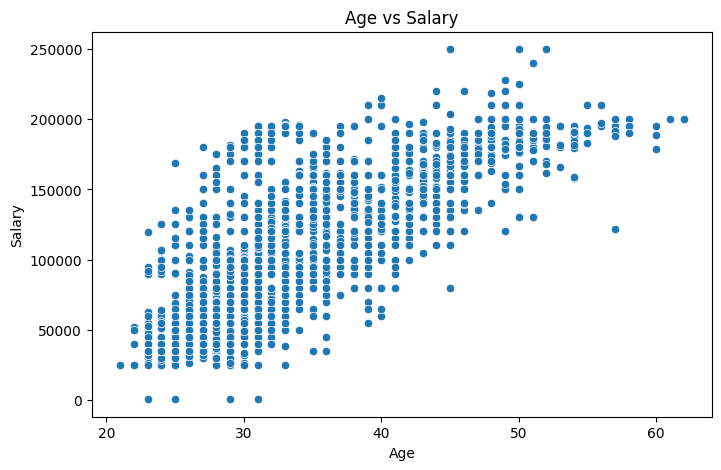

In [9]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Age",
    y="Salary",
    data=data
)

plt.title("Age vs Salary")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.show()


**Observation:** The scatter plot shows the relationship between employee age and salary.

### 6. Correlation Heatmap

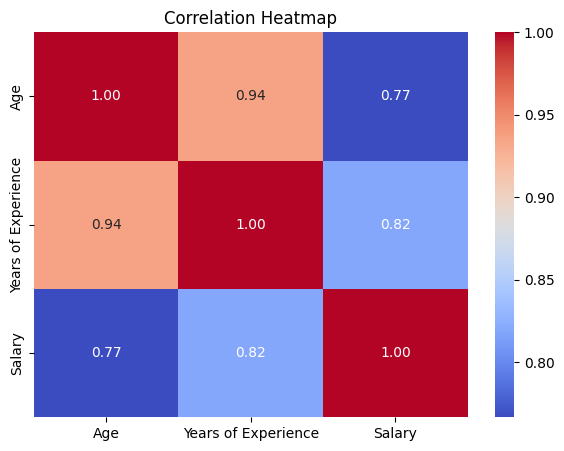

In [10]:
plt.figure(figsize=(7, 5))

corr = data[
    ["Age", "Years of Experience", "Salary"]
].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()


**Observation:** The heatmap shows the correlations between age, years of experience, and salary.

### 7. Top 10 Job Titles by Median Salary (Additional Plot)

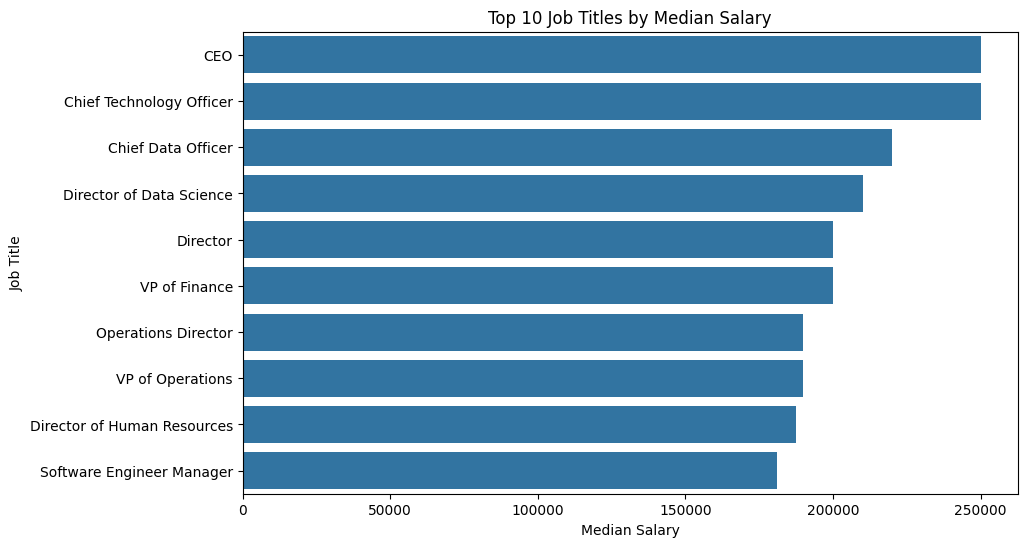

In [11]:
top_jobs = (
    data.groupby("Job Title")["Salary"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_jobs.values,
    y=top_jobs.index
)

plt.title("Top 10 Job Titles by Median Salary")
plt.xlabel("Median Salary")
plt.ylabel("Job Title")

plt.show()


**Observation:** Different job titles have different median salaries, showing that job role can be useful for salary prediction.

## 3.4 Model Building

In [12]:
from sklearn.model_selection import train_test_split

X = data.drop("Salary", axis=1)
y = data["Salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1430, 5)
Testing data: (358, 5)


### Encode Categorical Variables

The dataset contains categorical columns (`Gender`, `Education Level`, and `Job Title`). We use one-hot encoding.

The encoder is placed inside a pipeline so it is fitted using the training data only, helping avoid data leakage.


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features = [
    "Age",
    "Years of Experience"
]

categorical_features = [
    "Gender",
    "Education Level",
    "Job Title"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}


In [15]:
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully")


Linear Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


## 3.5 Evaluation

In [16]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

results = []

for name, model in trained_models.items():

    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, pred)

    results.append([
        name,
        mae,
        mse,
        rmse,
        r2
    ])

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
)

print(results_df)


               Model           MAE           MSE          RMSE  R2 Score
0  Linear Regression  14825.016783  3.987994e+08  19969.961933  0.854162
1      Decision Tree  17685.905157  5.705181e+08  23885.521580  0.791365
2      Random Forest  10350.365037  2.419036e+08  15553.249463  0.911537


### Metric Explanation

- **MAE:** Average absolute difference between actual and predicted salary. Lower is better.
- **MSE:** Average squared prediction error. Lower is better.
- **RMSE:** Square root of MSE and expressed in salary units. Lower is better.
- **R² Score:** Proportion of salary variation explained by the model. Higher is better.


### Cross Validation

In [17]:
from sklearn.model_selection import cross_val_score

for name, model in trained_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    print(
        name,
        "CV R2 Score:",
        round(scores.mean(), 4)
    )


Linear Regression CV R2 Score: 0.8322
Decision Tree CV R2 Score: 0.7937
Random Forest CV R2 Score: 0.8989


### Select Best Model

In [18]:
best_model_name = results_df.loc[
    results_df["R2 Score"].idxmax(),
    "Model"
]

print("Best Model:", best_model_name)

best_model = trained_models[best_model_name]

pred = best_model.predict(X_test)

print("\nBest Model Evaluation:")
print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mean_squared_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2 Score:", r2_score(y_test, pred))


Best Model: Random Forest

Best Model Evaluation:
MAE: 10350.365036824249
MSE: 241903568.8490681
RMSE: 15553.249462702903
R2 Score: 0.9115373840483492


### Actual vs Predicted Salary

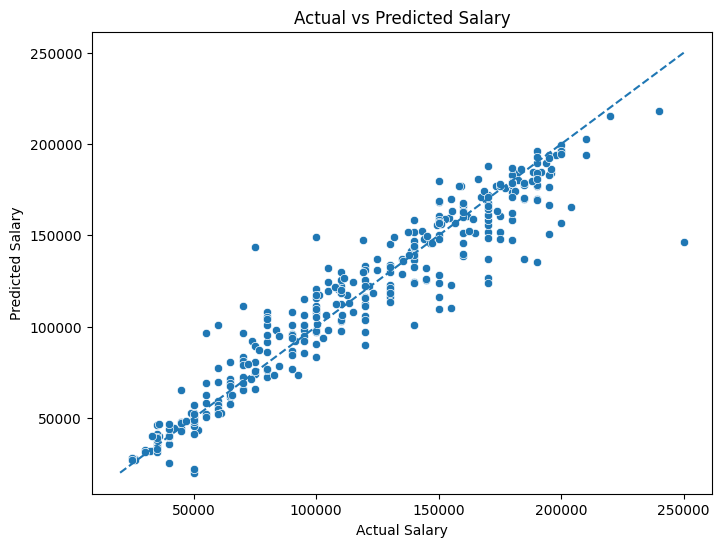

In [19]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=pred
)

low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())

plt.plot(
    [low, high],
    [low, high],
    linestyle="--"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")

plt.title("Actual vs Predicted Salary")

plt.show()


**Observation:** Points closer to the diagonal line indicate more accurate salary predictions.

### Residual Distribution

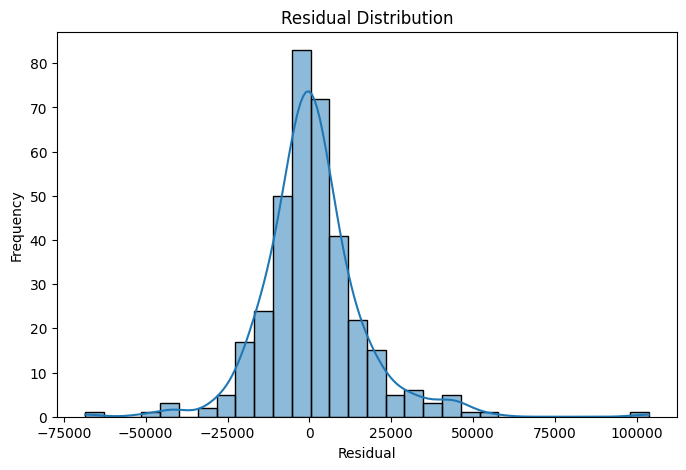

In [20]:
residuals = y_test - pred

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    kde=True,
    bins=30
)

plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.show()


**Observation:** Residuals distributed around zero indicate smaller systematic prediction errors.

### Feature Importance

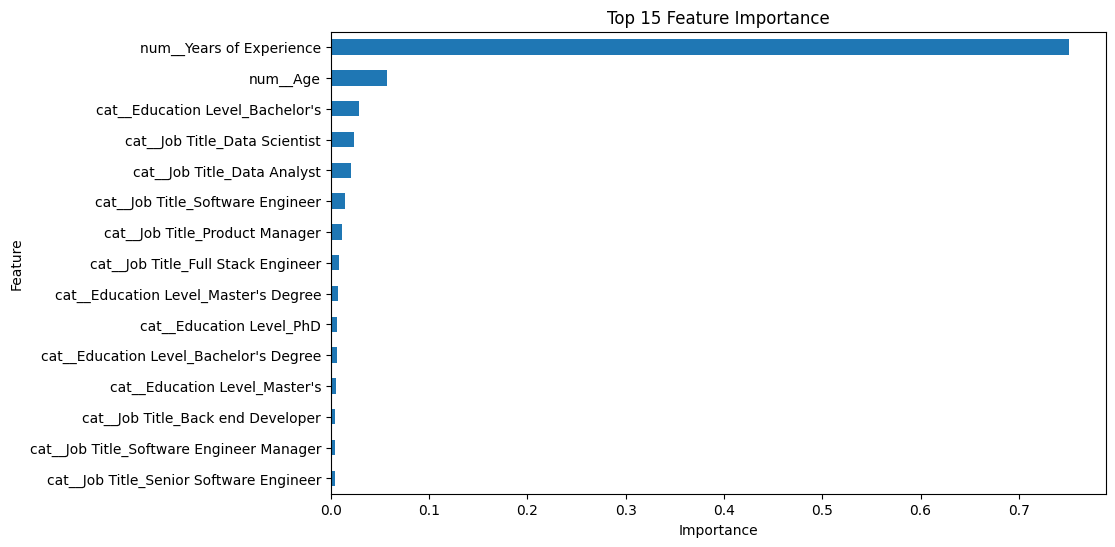

In [21]:
rf_model = trained_models["Random Forest"]

model = rf_model.named_steps["model"]

preprocessor_fitted = rf_model.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
)

importance = importance.sort_values(
    ascending=False
).head(15)

plt.figure(figsize=(10, 6))

importance.sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()


## 3.6 Interpreting the Results

### Model Comparison

Three regression models were compared: Linear Regression, Decision Tree Regressor, and Random Forest Regressor. The models were evaluated using MAE, MSE, RMSE, and R² score. The model with the highest R² score and lower prediction errors is considered the best-performing model.

### Important Features

Feature importance from the Random Forest model shows which encoded employee attributes contribute most to salary prediction. Job Title, Years of Experience, Education Level, and Age can provide useful information for predicting salary.

### Real-World Meaning

Salary can depend on factors such as job role, professional experience, education, and age. Therefore, these variables are reasonable inputs for an employee salary prediction model.

### Limitations

The dataset contains many job-title categories, which can create a large number of encoded features. Salary may also depend on factors not present in the dataset, such as location, company, industry, skills, and performance. Therefore, predictions should be treated as estimates.

### Future Improvements

- Hyperparameter tuning using GridSearchCV
- Gradient Boosting or other advanced regression models
- Grouping rare job titles
- Adding location, company, industry, and skill information
- Collecting a larger and consistently labeled dataset


## Example: Predict Salary for a New Employee

In [22]:
new_employee = pd.DataFrame({
    "Age": [30],
    "Gender": ["Male"],
    "Education Level": ["Bachelor's"],
    "Job Title": ["Software Engineer"],
    "Years of Experience": [5]
})

predicted_salary = best_model.predict(new_employee)[0]

print("Predicted Salary:", round(predicted_salary, 2))


Predicted Salary: 151397.98


## Conclusion

The Employee Salary Prediction project applies the complete data science workflow to a real employee dataset. The data was inspected, cleaned, visualized, and used to train three regression models. Cross-validation and regression metrics were used to compare model performance. The best model is selected using the actual R² results obtained from the dataset.

**References**
1. Provided 342IT Data Science Mini Project Guideline.
2. `Salary_Data.csv` supplied for this project.
3. pandas documentation.
4. matplotlib and seaborn documentation.
5. scikit-learn documentation.
